In [ ]:
# Import required libraries
import time
from types import SimpleNamespace
import requests
import zipfile
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.formula.api import glm
from scipy import stats
from sklearn.metrics import mean_poisson_deviance
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
import tensorflow as tf
from tensorflow import keras
from google.colab import files

from IPython.display import clear_output

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OrdinalEncoder,
    StandardScaler,
)


In [ ]:
# a helper to allow quick run of notebook
QUICK_MODE = False

def effective_epochs(n):
  if QUICK_MODE:
    print("WARNING: Not running all epochs due to QUICK_MODE")
    return 1
  else:
    return n

In [ ]:
# URL of the zip file
zip_url = "https://people.math.ethz.ch/~wueth/AITools/Data.zip"
zip_file_name = "Data.zip"

if not os.path.exists(zip_file_name):
  print(f"Downloading {zip_file_name}...")
  response = requests.get(zip_url)
  response.raise_for_status() # Raise an exception for HTTP errors

  with open(zip_file_name, "wb") as f:
      f.write(response.content)
else:
  print(f"{zip_file_name} already exists.")

# Unzip the file
print(f"Unzipping {zip_file_name}...")
with zipfile.ZipFile(zip_file_name, 'r') as zip_ref:
    zip_ref.extractall(".") # Extract to the current directory
print("Unzipping complete.")


Unzipping Data.zip...
Unzipping complete.


In [ ]:
df = pd.read_parquet("Data/freMTPL2freq.parquet")
print(df.info())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 678007 entries, 0 to 678006
Data columns (total 14 columns):
 #   Column      Non-Null Count   Dtype   
---  ------      --------------   -----   
 0   IDpol       678007 non-null  float64 
 1   Exposure    678007 non-null  float64 
 2   Area        678007 non-null  category
 3   VehPower    678007 non-null  int32   
 4   VehAge      678007 non-null  int32   
 5   DrivAge     678007 non-null  int32   
 6   BonusMalus  678007 non-null  int32   
 7   VehBrand    678007 non-null  category
 8   VehGas      678007 non-null  category
 9   Density     678007 non-null  int32   
 10  Region      678007 non-null  category
 11  ClaimTotal  678007 non-null  float64 
 12  ClaimNb     678007 non-null  float64 
 13  LearnTest   678007 non-null  object  
dtypes: category(4), float64(4), int32(5), object(1)
memory usage: 41.4+ MB
None


,IDpol,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,ClaimTotal,ClaimNb,LearnTest
0,4156370.0,0.06,D,6,6,20,100,B2,Regular,525,R82,0.0,0.0,L
1,4006798.0,0.29,E,6,7,29,59,B12,Diesel,2498,R72,0.0,0.0,L
2,6084964.0,0.46,C,7,10,27,68,B1,Diesel,123,R82,0.0,0.0,L
3,2228865.0,0.08,D,4,15,34,50,B2,Regular,1109,R24,0.0,0.0,L
4,4141911.0,1.00,A,5,22,44,50,B3,Diesel,34,R72,0.0,0.0,L


In [ ]:
mtpl = SimpleNamespace(
    training_data_raw = df[df.LearnTest == "L"].reset_index(drop=True),
    testing_data_raw = df[df.LearnTest == "T"].reset_index(drop=True),
)

In [ ]:
def preprocess_mtpl():
  """ for comparability the preprocessing as well as the data is taken from
  https://github.com/wueth/AITools4Actuaries/blob/main/Ch3_02_Poisson_GLM.ipynb"""

  # DrivAge: 31-40 is placed first so it becomes the GLM reference level
  _driv_age_bins = [17, 20, 25, 30, 40, 50, 70, 101]
  _driv_age_labels = ["18-20", "21-25", "26-30", "31-40", "41-50", "51-70", "71+"]
  _driv_age_ref_first = ["31-40"] + [lev for lev in _driv_age_labels if lev != "31-40"]

  # --- preprocessing functions specific for single covariates ---
  def _area_encode(X):
    """Map alphabetical area codes A-F to ordinal integers 1-6."""
    return (X.squeeze().cat.codes + 1.0).to_frame(name="AreaGLM")

  def _vehpower_clip(X):
    """Cap vehicle power at 9 and treat as categorical."""
    return pd.DataFrame({"VehPowerGLM": pd.Categorical(X.squeeze().clip(upper=9))})

  def _vehage_bin(X):
    """Bin vehicle age into three groups: 0-5, 6-12, 12+."""
    return pd.DataFrame({
            "VehAgeGLM": pd.cut(
                X.squeeze(), bins=[-1, 5, 12, 101], labels=["0-5", "6-12", "12+"]
            )})

  def _drivage_bin(X):
      """Bin driver age into seven groups with 31-40 as the reference level."""
      cuts = pd.cut(X.squeeze(), bins=_driv_age_bins, labels=_driv_age_labels)
      return pd.DataFrame(
          {"DrivAgeGLM": pd.Categorical(cuts, categories=_driv_age_ref_first)}
      )

  def _bonusmalus_clip(X):
      """Cap bonus-malus score at 150."""
      return pd.DataFrame({"BonusMalusGLM": X.squeeze().clip(upper=150)})

  def _density_log(X):
      """Log-transform population density."""
      return pd.DataFrame({"DensityGLM": np.log(X.squeeze())})

  def _ft(func, names):
      """Return a FunctionTransformer with fixed output column names."""
      return FunctionTransformer(
          func=func, feature_names_out=lambda self, _: names, check_inverse=False
      )

  # --- assemble the preprocessing pipeline ---
  preprocessor = ColumnTransformer(
    transformers=[
        ("area", _ft(_area_encode, ["AreaGLM"]), ["Area"]),
        ("vehpower", _ft(_vehpower_clip, ["VehPowerGLM"]), ["VehPower"]),
        ("vehage", _ft(_vehage_bin, ["VehAgeGLM"]), ["VehAge"]),
        ("drivage", _ft(_drivage_bin, ["DrivAgeGLM"]), ["DrivAge"]),
        ("bonusmalus", _ft(_bonusmalus_clip, ["BonusMalusGLM"]), ["BonusMalus"]),
        ("density", _ft(_density_log, ["DensityGLM"]), ["Density"]),
        ("passthrough", "passthrough", ["VehBrand", "VehGas", "ClaimNb", "Exposure"]),
    ],
    verbose_feature_names_out=False,
  )
  # Fit preprocessor on learning data only
  preprocessor.set_output(transform="pandas").fit(mtpl.training_data_raw)

  mtpl.training_data = preprocessor.transform(mtpl.training_data_raw).copy()
  mtpl.testing_data = preprocessor.transform(mtpl.testing_data_raw).copy()
preprocess_mtpl()



In [ ]:
# a global list of all models
model_list = []

In [ ]:
glm1 = SimpleNamespace(
    name = "glm1",
  description = "The baseline GLM from AITools4Actuaries",
  train = SimpleNamespace(target = mtpl.training_data["ClaimNb"],
                          exposure = mtpl.training_data['Exposure']),
  test = SimpleNamespace(target = mtpl.testing_data["ClaimNb"],
                         exposure = mtpl.testing_data['Exposure']),
)

glm1.model = glm(
      "ClaimNb ~ DrivAgeGLM + VehBrand + VehGas + DensityGLM + AreaGLM",
      data=mtpl.training_data,
      offset=np.log(mtpl.training_data["Exposure"]),
      family=sm.families.Poisson(),
  )

glm1.results = glm1.model.fit()
print(glm1.results.summary())
model_list.append(glm1)
glm1.train.prediction = glm1.results.predict(mtpl.training_data)
glm1.test.prediction = glm1.results.predict(mtpl.testing_data)


                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               610206
Model:                            GLM   Df Residuals:                   610186
Model Family:                 Poisson   Df Model:                           19
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -98513.
Date:                Mon, 26 Oct 2026   Deviance:                   1.5138e+05
Time:                        20:02:41   Pearson chi2:                 1.02e+06
No. Iterations:                     7   Pseudo R-squ. (CS):           0.004052
Covariance Type:            nonrobust                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -3.2590    

In [ ]:
def calculate_deviance(model_run):
  # Calculate in-sample and out-of-sample deviance using sklearn
  # For better visibility we scale with 100
  for dataset_name, dataset in [("Training", model_run.train), ("Testing", model_run.test)]:
    dataset.deviance = 100 * mean_poisson_deviance(
      dataset.target / dataset.exposure,
      dataset.prediction,
      sample_weight=dataset.exposure
    )

    actual_claims = np.asarray(dataset.target).ravel()
    exposure = np.asarray(dataset.exposure).ravel()
    predicted_rates = np.asarray(dataset.prediction).ravel()

    dataset.keras_poisson = np.mean(exposure * ( predicted_rates - actual_claims/exposure * np.log(predicted_rates) ) )

    predicted_claims = predicted_rates * exposure
    relative_scoring = actual_claims.sum() / predicted_claims.sum()
    print(f"{dataset_name} Deviance = {dataset.deviance:.3f} Keras Poisson = {dataset.keras_poisson:.5f}"
      f"  Total Actual Claims: {actual_claims.sum():.2f}"
      f"  Total Predicted Claims: {predicted_claims.sum():.2f}"
      f"  Relative Scoring (Actual / Predicted): {relative_scoring:.4f}")

calculate_deviance(glm1)

# check that we properly reproduce the base case from AITools4Actuaries
assert abs(glm1.train.deviance - 46.954) < 0.0006, f"training deviance is {glm1.train.deviance:.3f}, expected 46.954"
assert abs(glm1.test.deviance - 47.179) < 0.0006, f"test deviance is {glm1.test.deviance:.3f}, expected 47.179"

Training Deviance = 46.954 Keras Poisson = 0.13835  Total Actual Claims: 23738.00  Total Predicted Claims: 23738.00  Relative Scoring (Actual / Predicted): 1.0000
Testing Deviance = 47.179 Keras Poisson = 0.13874  Total Actual Claims: 2645.00  Total Predicted Claims: 2650.74  Relative Scoring (Actual / Predicted): 0.9978


### One-hot Encoding Categorical Features

Now, I'll create one-hot encoded versions of the training and testing dataframes. `pd.get_dummies` will automatically identify and convert categorical columns (object or category dtype) into a numerical format, which can be useful for other modeling approaches.

In [ ]:
features = ["DrivAgeGLM", "VehBrand", "VehGas", "DensityGLM", "AreaGLM"]

# Perform one-hot encoding on training and testing data
# pd.get_dummies automatically handles categorical (object/category) columns
mtpl.training_data_1h = pd.get_dummies(mtpl.training_data[features], drop_first=True, dtype=float)
mtpl.testing_data_1h = pd.get_dummies(mtpl.testing_data[features], drop_first=True, dtype=float)

print(mtpl.training_data_1h.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 610206 entries, 0 to 610205
Data columns (total 19 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   DensityGLM        610206 non-null  float64
 1   AreaGLM           610206 non-null  float64
 2   DrivAgeGLM_18-20  610206 non-null  float64
 3   DrivAgeGLM_21-25  610206 non-null  float64
 4   DrivAgeGLM_26-30  610206 non-null  float64
 5   DrivAgeGLM_41-50  610206 non-null  float64
 6   DrivAgeGLM_51-70  610206 non-null  float64
 7   DrivAgeGLM_71+    610206 non-null  float64
 8   VehBrand_B2       610206 non-null  float64
 9   VehBrand_B3       610206 non-null  float64
 10  VehBrand_B4       610206 non-null  float64
 11  VehBrand_B5       610206 non-null  float64
 12  VehBrand_B6       610206 non-null  float64
 13  VehBrand_B10      610206 non-null  float64
 14  VehBrand_B11      610206 non-null  float64
 15  VehBrand_B12      610206 non-null  float64
 16  VehBrand_B13      61

### Keras Feedforward Neural Network Setup

Now, I'll set up a Keras FNN. The network will consist of an input layer, and a dense output layer with `1` unit and `exponential` activation. The exponential activation function is chosen to mimic the log link function used in Poisson GLMs, which is suitable for count data (like claim numbers) as it ensures positive predictions.

In [ ]:
def glm_to_keras(params, keras_columns):
    """Return (kernel, bias) for a Keras Dense(1) layer."""
    p = params.copy()

    # statsmodels/Patsy names -> get_dummies names
    p.index = (p.index
               .str.replace(r"\[T\.(.*?)\]", r"_\1", regex=True))

    bias = p.pop("Intercept")
    kernel = p.reindex(keras_columns)

    if kernel.isna().any():
        raise ValueError(f"Missing GLM parameters: {kernel[kernel.isna()].index.tolist()}")

    return kernel.to_numpy().reshape(-1, 1), np.array([bias])

In [ ]:
# a less verbose training output
class OneLineProgress(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        val_loss = ""
        if "val_loss" in logs:
            val_loss = f" - val_loss: {logs['val_loss']:.6f}"
        print(
            f"\rEpoch {epoch + 1}/{self.params['epochs']} "
            f"- loss: {logs['loss']:.6f} {val_loss}",
            end="",
            flush=True,
        )

    def on_train_end(self, logs=None):
        print()

In [ ]:
def create_glm_linear_predictor(n_features, initializer):
    features_input = keras.Input(shape=(n_features,), name='features_input')

    init = {}
    if initializer is not None:
      weights, bias = initializer
      init['kernel_initializer'] = keras.initializers.Constant(weights)
      init['bias_initializer'] = keras.initializers.Constant(bias)

    linear_predictor = keras.layers.Dense(1, name='glm_linear_predictor', activation='linear', **init)(features_input)

    return linear_predictor, features_input


def glm_keras(name, data, initializer, split, batch_size, epochs, keep_best, description, seed=1234):
    tf.keras.utils.set_random_seed(seed)
    model_info = SimpleNamespace(
        name=name,
        description=description,
        constructor='glm_keras',
        initializer= initializer.name if initializer else "None",
        split=split,
        batch_size=batch_size,
        epochs=epochs,
        keep_best=keep_best,
        seed=seed,
        train = SimpleNamespace(target = data.training_data["ClaimNb"],
                            exposure = data.training_data['Exposure'],
                            input = data.training_data_1h),
    test = SimpleNamespace(target = data.testing_data["ClaimNb"],
                          exposure = data.testing_data['Exposure'],
                          input = data.testing_data_1h),
    )

    if initializer is not None:
      initializer = glm_to_keras(initializer.results.params, model_info.train.input.columns)

    input_shape = model_info.train.input.shape[1]

    linear_predictor, features_input = create_glm_linear_predictor(input_shape, initializer)


    dense_output = keras.layers.Activation("exponential")(linear_predictor)

    # Create the Keras Model
    model_info.model = keras.Model(inputs=features_input, outputs=dense_output)

    if epochs is not None:
      callbacks = [OneLineProgress()]
      if keep_best:
        callbacks.append(keras.callbacks.EarlyStopping(
          monitor="val_loss" if split else "loss",
          patience=epochs,          # effectively prevents early stopping
          restore_best_weights=True,
        ))

      model_info.model.compile(loss="poisson", optimizer="nadam")
      model_info.history = model_info.model.fit(
        model_info.train.input,
        model_info.train.target / model_info.train.exposure,
        sample_weight=model_info.train.exposure,
        validation_split=split,
        batch_size=batch_size,
        epochs=effective_epochs(epochs),
        verbose=0,
        callbacks=callbacks,
      )
    model_info.train.prediction = model_info.model(model_info.train.input, training=False).numpy()
    model_info.test.prediction = model_info.model(model_info.test.input, training=False).numpy()
    calculate_deviance(model_info)
    return model_info


In [ ]:
glm_keras_control = glm_keras("glm_keras_control", mtpl,
                              initializer=glm1, split=None, batch_size=None, epochs=None, keep_best=False,
                              description="A Keras/Tensorflow model implementing GLM and initialized with GLM coefficients, predicting rate")
glm_keras_control.model.summary()
model_list.append(glm_keras_control)

Training Deviance = 46.954 Keras Poisson = 0.13835  Total Actual Claims: 23738.00  Total Predicted Claims: 23738.00  Relative Scoring (Actual / Predicted): 1.0000
Testing Deviance = 47.179 Keras Poisson = 0.13874  Total Actual Claims: 2645.00  Total Predicted Claims: 2650.74  Relative Scoring (Actual / Predicted): 0.9978


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features_input (InputLayer)     │ (None, 19)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ glm_linear_predictor (Dense)    │ (None, 1)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20 (80.00 B)

 Trainable params: 20 (80.00 B)

 Non-trainable params: 0 (0.00 B)

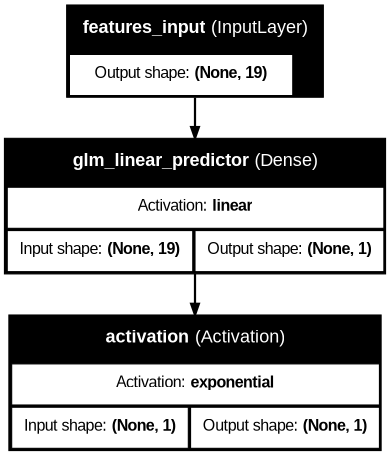

In [ ]:
keras.utils.plot_model(
    glm_keras_control.model,
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,
    expand_nested=True,
    dpi=80,
)

In [ ]:
for batch_size, epochs in [(5000,200), (50000, 2000), (200000, 4000)]:
  for split in [None, 0.1]:
    model_list.append(
        glm_keras("glm_keras_trained", mtpl,
                  initializer=None, split=split, batch_size=batch_size, epochs=epochs, keep_best=True,
                  description=f"A Keras/Tensorflow model implementing GLM"))
    model_list.append(
        glm_keras("glm_keras_train_init", mtpl,
                  initializer=glm1, split=split, batch_size=batch_size, epochs=epochs//10, keep_best=False,
                  description=f"A Keras/Tensorflow model implementing GLM and initialized with GLM coefficients")
        )


Epoch 200/200 - loss: 0.138385 
Training Deviance = 46.961 Keras Poisson = 0.13837  Total Actual Claims: 23738.00  Total Predicted Claims: 23514.94  Relative Scoring (Actual / Predicted): 1.0095
Testing Deviance = 47.200 Keras Poisson = 0.13879  Total Actual Claims: 2645.00  Total Predicted Claims: 2626.10  Relative Scoring (Actual / Predicted): 1.0072
Epoch 20/20 - loss: 0.138371 
Training Deviance = 46.956 Keras Poisson = 0.13836  Total Actual Claims: 23738.00  Total Predicted Claims: 23480.13  Relative Scoring (Actual / Predicted): 1.0110
Testing Deviance = 47.189 Keras Poisson = 0.13876  Total Actual Claims: 2645.00  Total Predicted Claims: 2621.82  Relative Scoring (Actual / Predicted): 1.0088
Epoch 200/200 - loss: 0.138487  - val_loss: 0.137437
Training Deviance = 47.005 Keras Poisson = 0.13849  Total Actual Claims: 23738.00  Total Predicted Claims: 22961.30  Relative Scoring (Actual / Predicted): 1.0338
Testing Deviance = 47.250 Keras Poisson = 0.13893  Total Actual Claims: 2645

KeyboardInterrupt: 

In [ ]:
results_data = []

for model_info in model_list:
    train_actual_claims = np.asarray(model_info.train.target).ravel()
    train_exposure = np.asarray(model_info.train.exposure).ravel()
    train_predicted_rates = np.asarray(model_info.train.prediction).ravel()
    train_predicted_claims = train_predicted_rates * train_exposure
    train_relative_scoring = train_actual_claims.sum() / train_predicted_claims.sum()

    test_actual_claims = np.asarray(model_info.test.target).ravel()
    test_exposure = np.asarray(model_info.test.exposure).ravel()
    test_predicted_rates = np.asarray(model_info.test.prediction).ravel()
    test_predicted_claims = test_predicted_rates * test_exposure
    test_relative_scoring = test_actual_claims.sum() / test_predicted_claims.sum()

    results_data.append({
        'name': getattr(model_info, 'name', None),
        'initializer': getattr(model_info, 'initializer', None),
        'batch_size': getattr(model_info, 'batch_size', None),
        'epochs': getattr(model_info, 'epochs', None),
        'keep_best': getattr(model_info, 'keep_best', None),
        'split': getattr(model_info, 'split', None),
        'train_deviance': getattr(model_info.train, 'deviance', None),
        'train_relative_scoring': train_relative_scoring,
        'test_deviance': getattr(model_info.test, 'deviance', None),
        'test_relative_scoring': test_relative_scoring
    })

results_df = pd.DataFrame(results_data)
display(results_df)

,name,initializer,batch_size,epochs,keep_best,split,train_deviance,train_relative_scoring,test_deviance,test_relative_scoring
0,glm1,None,NaN,NaN,None,NaN,46.953720,1.000000,47.178625,0.997834
1,glm_keras_control,glm1,NaN,NaN,False,NaN,46.953720,1.000000,47.178625,0.997834
2,glm_keras_trained,None,5000.0,200.0,True,NaN,46.961176,1.009486,47.200002,1.007197
3,glm_keras_train_init,glm1,5000.0,20.0,False,NaN,46.955965,1.010982,47.188533,1.008840
4,glm_keras_trained,None,5000.0,200.0,True,0.1,47.004507,1.033826,47.250422,1.031282
5,glm_keras_train_init,glm1,5000.0,20.0,False,0.1,46.966796,1.038821,47.196992,1.036688
6,glm_keras_trained,None,50000.0,2000.0,True,NaN,46.954512,1.002555,47.174250,1.000332
7,glm_keras_train_init,glm1,50000.0,200.0,False,NaN,46.954442,1.002634,47.173778,1.000420


In [ ]:
# Map model names
name_mapping = {
    'glm1': 'GLM (statsmodels)',
    'glm_keras_control': 'Keras Control',
    'glm_keras_trained': 'Keras Trained',
    'glm_keras_train_init': 'Keras Stability Test'
}

# Filter df to only contain the selected models
table_df = results_df[results_df['name'].isin(name_mapping.keys())].copy()
table_df['name'] = table_df['name'].map(name_mapping)

# Keep and rename the requested columns directly with LaTeX headers using single braces
column_mapping = {
    'name': 'Model Name',
    'batch_size': '\\makecell{Batch\\\\Size}',
    'epochs': '\\makecell{Epochs}',
    'split': 'Split',
    'train_deviance': '\\makecell{Train\\\\Dev.}',
    'train_relative_scoring': '\\makecell{Train\\\\Cal.}',
    'test_deviance': '\\makecell{Test\\\\Dev.}',
    'test_relative_scoring': '\\makecell{Test\\\\Cal.}'
}

table_df = table_df[list(column_mapping.keys())].rename(columns=column_mapping)

# Define formatting functions for the Styler
def format_integer(val):
    if pd.isna(val):
        return '-'
    return f"{int(val):,}".replace(',', '\\,')

def format_split(val):
    if val == 0.1:
        return '90/10'
    return '-'

# Create and apply styling via pandas Styler with single braces
styled = table_df.style.format({
    '\\makecell{Batch\\\\Size}': format_integer,
    '\\makecell{Epochs}': format_integer,
    'Split': format_split,
    '\\makecell{Train\\\\Dev.}': "{:.4f}",
    '\\makecell{Train\\\\Cal.}': "{:.4f}",
    '\\makecell{Test\\\\Dev.}': "{:.4f}",
    '\\makecell{Test\\\\Cal.}': "{:.4f}"
})

# Hide index and configure LaTeX export
latex_table = styled.hide(axis="index").to_latex(
    column_format="l r r c r r r r",
    hrules=True,
    environment=None
)

# Write and download the LaTeX table
with open('glm_keras.tex', 'w') as f:
    f.write(latex_table)

files.download('glm_keras.tex')

print("Saved styled LaTeX table to glm_keras.tex (without double braces)")
display(table_df)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved styled LaTeX table to glm_keras.tex (without double braces)


,Model Name,\makecell{Batch\\Size},\makecell{Epochs},Split,\makecell{Train\\Dev.},\makecell{Train\\Cal.},\makecell{Test\\Dev.},\makecell{Test\\Cal.}
0,GLM (statsmodels),NaN,NaN,NaN,46.953720,1.000000,47.178625,0.997834
1,Keras Control,NaN,NaN,NaN,46.953720,1.000000,47.178625,0.997834
2,Keras Trained,5000.0,200.0,NaN,46.961176,1.009486,47.200002,1.007197
3,Keras Stability Test,5000.0,20.0,NaN,46.955965,1.010982,47.188533,1.008840
4,Keras Trained,5000.0,200.0,0.1,47.004507,1.033826,47.250422,1.031282
5,Keras Stability Test,5000.0,20.0,0.1,46.966796,1.038821,47.196992,1.036688
6,Keras Trained,50000.0,2000.0,NaN,46.954512,1.002555,47.174250,1.000332
7,Keras Stability Test,50000.0,200.0,NaN,46.954442,1.002634,47.173778,1.000420


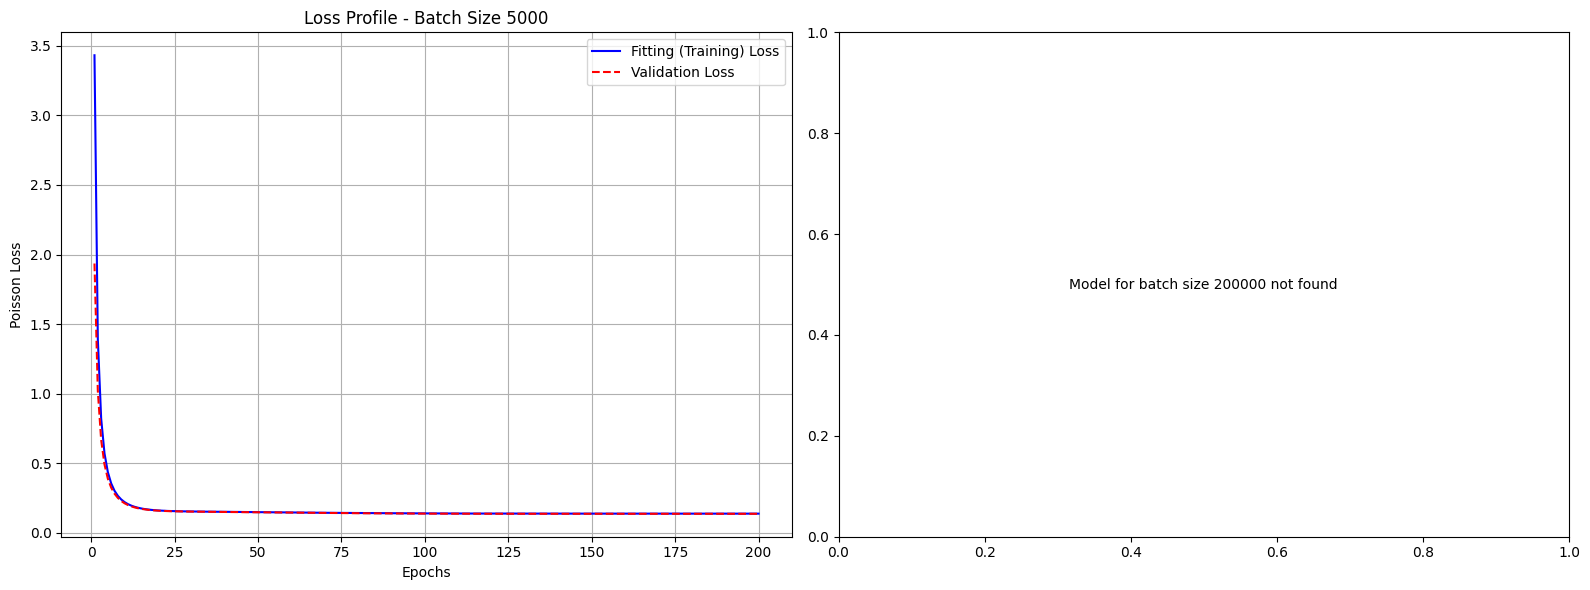

In [ ]:
import matplotlib.pyplot as plt

# Find the models with split=0.1, constructor='glm_keras', name='glm_keras_trained'
# and batch_size in [5000, 200000]
plot_models = {}
for m in model_list:
    if (
        getattr(m, 'constructor', None) == 'glm_keras'
        and getattr(m, 'name', None) == 'glm_keras_trained'
        and getattr(m, 'split', None) == 0.1
        and getattr(m, 'batch_size', None) in [5000, 200000]
        and hasattr(m, 'history')
    ):
        plot_models[m.batch_size] = m

# Create the plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=False)

for ax, batch_size in zip(axes, [5000, 200000]):
    if batch_size in plot_models:
        m = plot_models[batch_size]
        history = m.history.history
        epochs = range(1, len(history['loss']) + 1)

        ax.plot(epochs, history['loss'], 'b-', label='Fitting (Training) Loss')
        if 'val_loss' in history:
            ax.plot(epochs, history['val_loss'], 'r--', label='Validation Loss')

        ax.set_title(f'Loss Profile - Batch Size {batch_size}')
        ax.set_xlabel('Epochs')
        ax.set_ylabel('Poisson Loss')
        ax.legend()
        ax.grid(True)
    else:
        ax.text(0.5, 0.5, f'Model for batch size {batch_size} not found',
                horizontalalignment='center', verticalalignment='center')

plt.tight_layout()
plt.show()

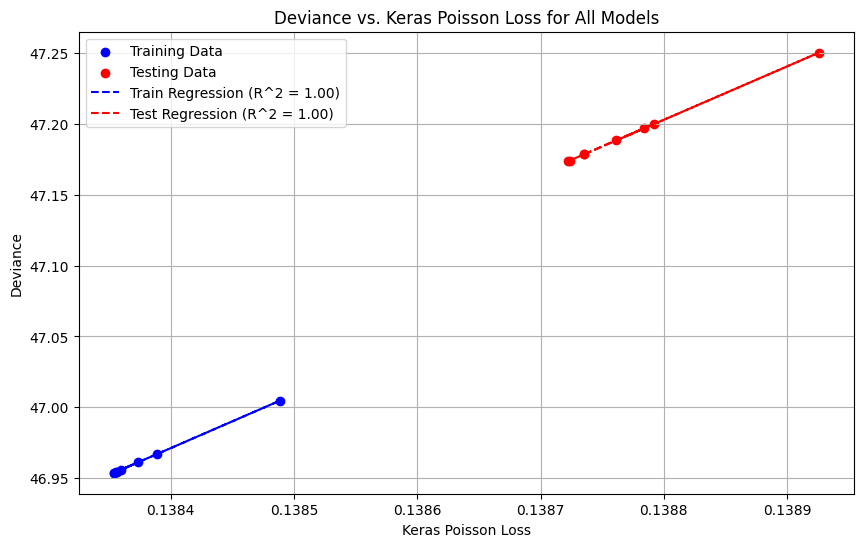

In [ ]:
train_deviance_values = []
train_keras_poisson_values = []
test_deviance_values = []
test_keras_poisson_values = []

for model_info in model_list:
    if hasattr(model_info, 'train') and hasattr(model_info.train, 'deviance') and hasattr(model_info.train, 'keras_poisson') \
       and hasattr(model_info, 'test') and hasattr(model_info.test, 'deviance') and hasattr(model_info.test, 'keras_poisson'):


        if model_info.train.keras_poisson > 0.2: continue

        train_deviance_values.append(model_info.train.deviance)
        train_keras_poisson_values.append(model_info.train.keras_poisson)
        test_deviance_values.append(model_info.test.deviance)
        test_keras_poisson_values.append(model_info.test.keras_poisson)

plt.figure(figsize=(10, 6))
plt.scatter(train_keras_poisson_values, train_deviance_values, color='blue', label='Training Data')
plt.scatter(test_keras_poisson_values, test_deviance_values, color='red', label='Testing Data')

# Calculate and plot regression line for training data
if len(train_keras_poisson_values) > 1:
    slope_train, intercept_train, r_value_train, p_value_train, std_err_train = stats.linregress(train_keras_poisson_values, train_deviance_values)
    plt.plot(train_keras_poisson_values, intercept_train + slope_train * np.array(train_keras_poisson_values), color='blue', linestyle='--', label=f'Train Regression (R^2 = {r_value_train**2:.2f})')

# Calculate and plot regression line for testing data
if len(test_keras_poisson_values) > 1:
    slope_test, intercept_test, r_value_test, p_value_test, std_err_test = stats.linregress(test_keras_poisson_values, test_deviance_values)
    plt.plot(test_keras_poisson_values, intercept_test + slope_test * np.array(test_keras_poisson_values), color='red', linestyle='--', label=f'Test Regression (R^2 = {r_value_test**2:.2f})')

plt.xlabel('Keras Poisson Loss')
plt.ylabel('Deviance')
plt.title('Deviance vs. Keras Poisson Loss for All Models')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
slope_test, slope_train

(np.float64(377.0220488394254), np.float64(378.54879552316424))

In [ ]:
print(results_df.to_csv())

,name,initializer,batch_size,epochs,keep_best,split,train_deviance,train_relative_scoring,test_deviance,test_relative_scoring
0,glm1,,,,,,46.95371991826694,0.9999999999999999,47.178624614533234,0.9978337569528617
1,glm_keras_control,glm1,,,False,,46.95371993382527,1.0000000577165022,47.17862459324254,0.9978338152497522
2,glm_keras_trained,None,5000.0,200.0,True,,46.96117641623519,1.0094857920913891,47.200002476252145,1.0071965660621236
3,glm_keras_train_init,glm1,5000.0,20.0,False,,46.955964680259335,1.0109824830617338,47.1885330543485,1.0088397059033587
4,glm_keras_trained,None,5000.0,200.0,True,0.1,47.004506891339695,1.0338262802534621,47.25042187214594,1.03128196782706
5,glm_keras_train_init,glm1,5000.0,20.0,False,0.1,46.96679550048944,1.038821383193966,47.196991567659126,1.0366882183454642
6,glm_keras_trained,None,50000.0,2000.0,True,,46.95451245068428,1.002555050816316,47.17424960645633,1.0003317165269787
7,glm_keras_train_init,glm1,50000.0,200.0,False,,46.95444188671286,1.0026338

In [ ]:
def write_latex_tables():
  names = {
    "batch_size": "Batch size",
    "epochs": "Epochs",
    "split": "Validation",
    "regularizer": "Regularizer",
    "train_deviance": "Train dev.",
    "train_relative_scoring": "Train O/E",
    "test_deviance": "Test dev.",
    "test_relative_scoring": "Test O/E",
  }

  # Only keep keys that are actually present in results_df
  available_keys = [k for k in names.keys() if k in results_df.columns]
  rename_dict = {k: names[k] for k in available_keys}
  format_dict = {
    "Batch size": "{:.0f}",
    "Epochs": "{:.0f}",
    "Validation": "{:.1f}",
    "Regularizer": "{:.4f}",
    "Train dev.": "{:.3f}",
    "Train O/E": "{:.4f}",
    "Test dev.": "{:.3f}",
    "Test O/E": "{:.4f}",
  }
  # Filter the format dictionary to only include renamed columns that are present
  active_formats = {k: v for k, v in format_dict.items() if k in rename_dict.values()}

  # MLE-initialised
  table_mle = (
      results_df.loc[results_df["initializer"] == "glm1", available_keys]
      .sort_values([col for col in ["batch_size", "split"] if col in available_keys], na_position="first")
  ).rename(columns=rename_dict)

  latex_mle = (
    table_mle.style
    .format(active_formats, na_rep="")
    .hide(axis="index")
    .to_latex(
        hrules=True,
        caption="Drift away from MLE",
        label="tab:glm_keras_mle_init",
    )
  )

  # Randomly initialised
  table_random = (
      results_df.loc[
          (results_df["initializer"].isna()) | (results_df["initializer"] == "None") | (results_df.get("fnn_initializer", pd.Series(dtype=object)).isna()) | (results_df.get("fnn_initializer", None) == "zero") | (results_df.get("fnn_initializer", None) == "mean"), available_keys
      ]
      .sort_values([col for col in ["batch_size", "split"] if col in available_keys], na_position="first")
  ).rename(columns=rename_dict)

  latex_rnd = (
    table_random.style
    .format(active_formats, na_rep="")
    .hide(axis="index")
    .to_latex(
        hrules=True,
        caption="Comparison of GLM estimation procedures.",
        label="tab:glm_keras_comparison",
    )
  )

  filename = "glm_keras_mle_init.tex"
  with open(filename, "w", encoding="utf-8") as f:
    f.write(latex_mle)
  files.download(filename)

  filename = "glm_keras_comparison.tex"
  with open(filename, "w", encoding="utf-8") as f:
    f.write(latex_rnd)
  files.download(filename)

write_latex_tables()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

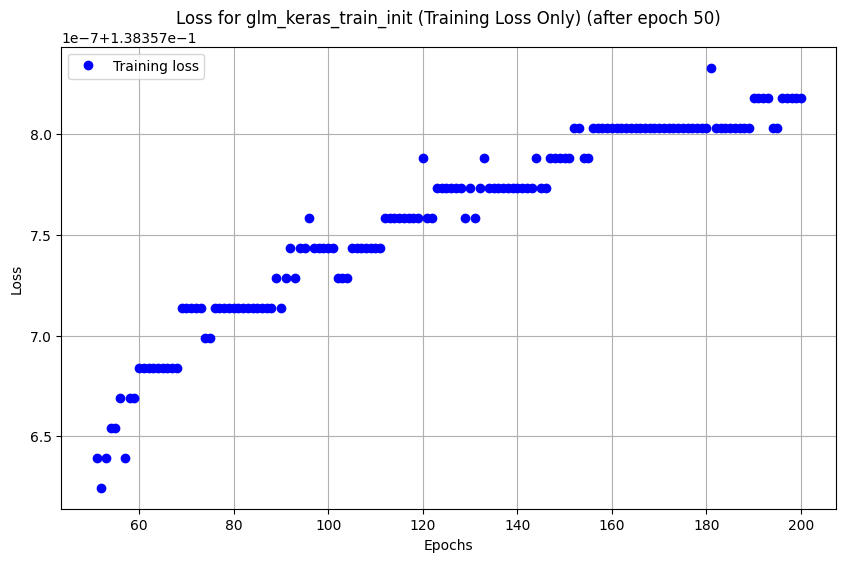

In [ ]:
model_to_plot = model_list[-1]

if hasattr(model_to_plot, 'history'):
    history = model_to_plot.history.history
    epochs_to_skip = 50

    plt.figure(figsize=(10, 6))

    # Extract and plot training loss
    loss = history['loss'][epochs_to_skip:]
    epochs = range(epochs_to_skip + 1, len(history['loss']) + 1)
    plt.plot(epochs, loss, 'bo', label='Training loss')
    title_suffix = ""

    # Conditionally extract and plot validation loss
    if 'val_loss' in history:
        val_loss = history['val_loss'][epochs_to_skip:]
        plt.plot(epochs, val_loss, 'b', label='Validation loss')
        title_suffix = "(Training and Validation Loss)"
    else:
        title_suffix = "(Training Loss Only)"

    plt.title(f'Loss for {model_to_plot.name} {title_suffix} (after epoch {epochs_to_skip})')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print(f"Model {model_to_plot.name} does not have a history object to plot.")

FNN from AI 4 actuaries

In [ ]:
#QUICK_MODE = False

In [ ]:
def clip_and_scale(upper):
    pipe = Pipeline(
        steps=[
            ("clip", FunctionTransformer(lambda x: np.clip(x, a_min=0, a_max=upper))),
            ("scale", StandardScaler()),
        ]
    )
    return pipe


density = Pipeline(
    steps=[
        ("log", FunctionTransformer(lambda x: np.log(x).round(2))),
        ("scale", StandardScaler()),
    ]
)

area = Pipeline(
    steps=[
        ("encode", OrdinalEncoder()),
        ("scale", StandardScaler()),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "scale",
            clip_and_scale([20, 90, 150, 15]),
            ["VehAge", "DrivAge", "BonusMalus", "VehPower"],
        ),
        ("area", area, ["Area"]),
        ("density", density, ["Density"]),
        ("veh_gas", FunctionTransformer(lambda x: x == "Diesel"), ["VehGas"]),
        ("veh_brand", OrdinalEncoder(), ["VehBrand", "Region"]),
    ],
    verbose_feature_names_out=False,
)



X_learn = preprocessor.fit_transform(mtpl.training_data_raw)
X_test = preprocessor.transform(mtpl.testing_data_raw)

y_learn, v_learn = mtpl.training_data_raw.ClaimNb, glm1.train.prediction
y_test, v_test = mtpl.testing_data_raw.ClaimNb, glm1.test.prediction

# Just a check: Fit preprocessor to training data and apply to some lines from test
preprocessor.set_output(transform="pandas").fit(mtpl.training_data_raw)
preprocessor.transform(mtpl.testing_data_raw.head())

,VehAge,DrivAge,BonusMalus,VehPower,Area,Density,VehGas,VehBrand,Region
0,-1.29173,-1.309026,1.937902,-1.196789,0.513423,0.298236,False,3.0,14.0
1,-1.29173,-0.884378,2.578711,-0.709264,0.513423,0.795155,False,3.0,0.0
2,-1.29173,-0.884378,2.578711,-0.709264,0.513423,0.795155,False,3.0,0.0
3,-1.29173,1.663510,-0.497176,-0.709264,0.513423,0.666918,False,3.0,0.0
4,-1.29173,0.460341,-0.625338,-0.709264,-0.209473,-0.476529,False,3.0,20.0


In [ ]:
# define FNN with entity embedding and three hidden layers
def create_fnn_linear_predictor(n_features, hidden_layers, kk, bb, kernel_regularizer, final_bias, freeze_hidden=False):
    design_input = keras.layers.Input(shape=(n_features,))

    # Extract brand and region features (last two columns)
    brand_input = keras.layers.Lambda(lambda x: x[:, -2:-1])(design_input)
    region_input = keras.layers.Lambda(lambda x: x[:, -1:])(design_input)

    # Embedding layers
    brand_embed = keras.layers.Embedding(input_dim=kk[0], output_dim=bb[0], trainable=not freeze_hidden)(brand_input)
    brand_embed = keras.layers.Flatten()(brand_embed)

    region_embed = keras.layers.Embedding(input_dim=kk[1], output_dim=bb[1], trainable=not freeze_hidden)(region_input)
    region_embed = keras.layers.Flatten()(region_embed)

    # Continuous features (all except last two columns)
    continuous_features = keras.layers.Lambda(lambda x: x[:, :-2])(design_input)

    # Concatenate all features
    x = keras.layers.Concatenate()([continuous_features, brand_embed, region_embed])

    # build the network
    for q in hidden_layers:
        x = keras.layers.Dense(q, activation="tanh", trainable=not freeze_hidden, kernel_regularizer=kernel_regularizer)(x)

    linear_predictor = keras.layers.Dense(1, activation="linear", name='fnn_linear_predictor', kernel_regularizer=kernel_regularizer, use_bias=final_bias)(x)

    return linear_predictor, design_input


def create_fnn(seed, n_features, hidden_layers, kk, bb, kernel_regularizer):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    glm_prediction_input = keras.layers.Input(shape=(1,))

    linear_predictor, design_input  = create_fnn_linear_predictor(n_features, hidden_layers, kk, bb, kernel_regularizer, final_bias=True)
    correction = keras.layers.Activation("exponential")(linear_predictor)

    output = keras.layers.Multiply()([correction, glm_prediction_input])

    model = keras.Model(inputs=[design_input, glm_prediction_input], outputs=output)

    return model

In [ ]:
def cann(name, data, initializer, use_glm, split, batch_size, epochs, keep_best, description, seed=1234):
    tf.keras.utils.set_random_seed(seed)

    if use_glm:
      glm_factor = 1
    else:
      glm_factor = 0

    model_info = SimpleNamespace(
        name=name,
        description=description,
        constructor='cann',
        initializer= initializer if initializer else "None",
        split=split,
        batch_size=batch_size,
        epochs=epochs,
        keep_best=keep_best,
        seed=seed,
        regularizer = 'none',
        train = SimpleNamespace(target = y_learn,
                            exposure = mtpl.training_data['Exposure'],
                            input = (X_learn, v_learn * glm_factor + (1-glm_factor))),
    test = SimpleNamespace(target = y_test,
                          exposure = mtpl.testing_data['Exposure'],
                          input = (X_test, v_test * glm_factor + (1-glm_factor))),
    )


    HIDDEN = [20, 15, 10]
    M_FEAT = X_learn.shape[1]
    KK = [len(mtpl.training_data_raw['VehBrand'].unique()), len(mtpl.training_data_raw['Region'].unique())]
    BB  = [2,2]


    # Create model with three hidden layers
    model_info.model = create_fnn(seed, M_FEAT, HIDDEN, KK, BB, None)

    if initializer == 'zero':
      w0 = model_info.model.get_weights()
      w0[-2] *= 0
      w0[-1] *= 0
      model_info.model.set_weights(w0)

    elif initializer == 'mean':
      w0 = model_info.model.get_weights()
      w0[-2] *= 0
      w0[-1][...] = np.log(model_info.train.target.sum() / model_info.train.exposure.sum())
      model_info.model.set_weights(w0)



    if epochs is not None:
      callbacks = [OneLineProgress()]
      if keep_best:
        callbacks.append(keras.callbacks.EarlyStopping(
          monitor="val_loss" if split else "loss",
          patience=epochs,          # effectively prevents early stopping
          restore_best_weights=True,
        ))

      model_info.model.compile(loss="poisson", optimizer="nadam")
      model_info.history = model_info.model.fit(
        model_info.train.input,
        model_info.train.target / model_info.train.exposure,
        sample_weight=model_info.train.exposure,
        validation_split=split,
        batch_size=batch_size,
        epochs=effective_epochs(epochs),
        verbose=0,
        callbacks=callbacks,
      )
    model_info.train.prediction = model_info.model(model_info.train.input, training=False).numpy()
    model_info.test.prediction = model_info.model(model_info.test.input, training=False).numpy()
    calculate_deviance(model_info)
    return model_info


In [ ]:
model_list.append(cann('cann_glm_only', mtpl, 'zero', True, None, None, None, None, 'reproduce GLM with cann setup'))

Training Deviance = 46.954 Keras Poisson = 0.13835  Total Actual Claims: 23738.00  Total Predicted Claims: 23738.00  Relative Scoring (Actual / Predicted): 1.0000
Testing Deviance = 47.179 Keras Poisson = 0.13874  Total Actual Claims: 2645.00  Total Predicted Claims: 2650.74  Relative Scoring (Actual / Predicted): 0.9978


In [ ]:
model_list.append(cann('cann', mtpl, None, True, 0.1, 5000, 200, True, 'cann with fixed glm offset'))

Epoch 107/200 - loss: 0.133187  - val_loss: 0.132140

KeyboardInterrupt: 

In [ ]:
model_list.append(cann('cann_no_glm', mtpl, None, False, 0.1, 5000, 200, True, 'cann with fnn only'))

In [ ]:
model_list.append(cann('cann_no_glm_mean_init', mtpl, 'mean', False, 0.1, 5000, 200, True, 'cann with fnn only'))

In [ ]:
def plot_history(model_to_plot, epochs_to_skip = 50):
    history = model_to_plot.history.history


    plt.figure(figsize=(10, 6))

    # Extract and plot training loss
    loss = history['loss'][epochs_to_skip:]
    epochs = range(epochs_to_skip + 1, len(history['loss']) + 1)
    plt.plot(epochs, loss, 'bo', label='Training loss')
    title_suffix = ""

    # Conditionally extract and plot validation loss
    if 'val_loss' in history:
        val_loss = history['val_loss'][epochs_to_skip:]
        plt.plot(epochs, val_loss, 'b', label='Validation loss')
        title_suffix = "(Training and Validation Loss)"
    else:
        title_suffix = "(Training Loss Only)"

    plt.title(f'Loss for {model_to_plot.name} {title_suffix} (after epoch {epochs_to_skip})')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
def plot_history2(model1, model2, epochs_to_skip=50):
    plt.figure(figsize=(12, 7))

    # Plot history for Model 1 (blue)
    if hasattr(model1, 'history'):
        history1 = model1.history.history
        loss1 = history1['loss'][epochs_to_skip:]
        epochs1 = range(epochs_to_skip + 1, len(history1['loss']) + 1)
        plt.plot(epochs1, loss1, 'bo-', label=f'{model1.name} Training loss')

        if 'val_loss' in history1:
            val_loss1 = history1['val_loss'][epochs_to_skip:]
            plt.plot(epochs1, val_loss1, 'b--', label=f'{model1.name} Validation loss')

    # Plot history for Model 2 (red)
    if hasattr(model2, 'history'):
        history2 = model2.history.history
        loss2 = history2['loss'][epochs_to_skip:]
        epochs2 = range(epochs_to_skip + 1, len(history2['loss']) + 1)
        plt.plot(epochs2, loss2, 'ro-', label=f'{model2.name} Training loss')

        if 'val_loss' in history2:
            val_loss2 = history2['val_loss'][epochs_to_skip:]
            plt.plot(epochs2, val_loss2, 'r--', label=f'{model2.name} Validation loss')

    plt.title(f'Training History Comparison (after epoch {epochs_to_skip})')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

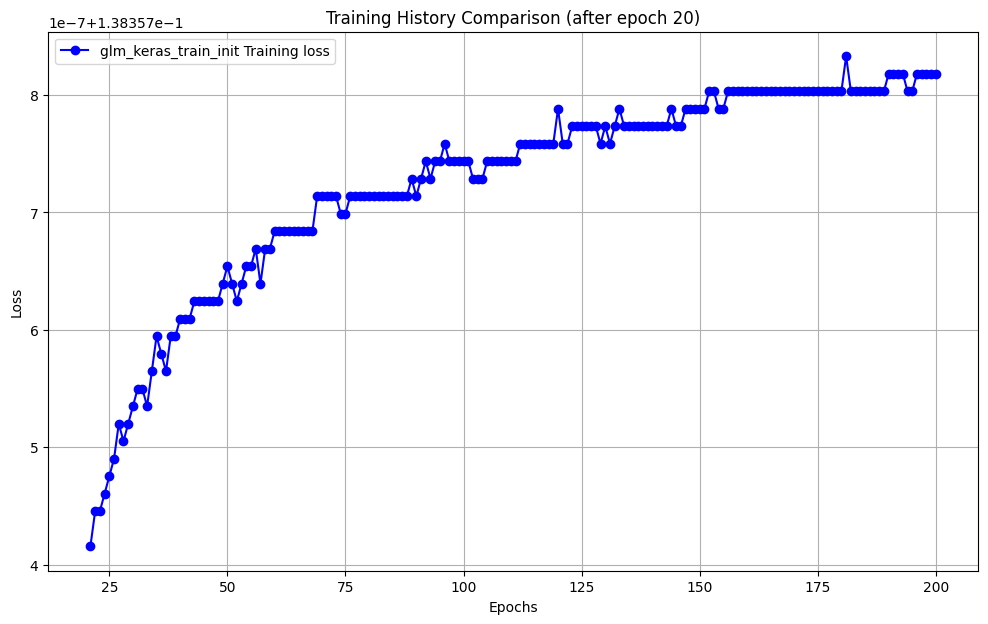

In [ ]:
plot_history2(model_list[-2], model_list[-1], 20)

In [ ]:
def create_mixed(seed, n_features, hidden_layers, kk, bb, kernel_regularizer, n_glm_features, glm_initializer):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    fnn_linear_predictor, design_input = create_fnn_linear_predictor(n_features, hidden_layers, kk, bb, kernel_regularizer, final_bias=False)
    glm_linear_predictor, glm_input = create_glm_linear_predictor(n_glm_features, glm_initializer)

    linear_predictor = keras.layers.Add()([fnn_linear_predictor, glm_linear_predictor])

    output = keras.layers.Activation("exponential")(linear_predictor)

    model = keras.Model(inputs=[design_input, glm_input], outputs=output)

    return model

def regularized_glm_nn(name, data, fnn_initializer, glm_initializer, split, batch_size, epochs, keep_best, reg, description, seed=1234):
    tf.keras.utils.set_random_seed(seed)

    model_info = SimpleNamespace(
        name=name,
        description=description,
        constructor='regularized_glm_nn',
        fnn_initializer=fnn_initializer,
        glm_initializer=glm_initializer,
        split=split,
        batch_size=batch_size,
        epochs=epochs,
        keep_best=keep_best,
        seed=seed,
        regularizer = str(reg),
        train = SimpleNamespace(target = y_learn,
                            exposure = mtpl.training_data['Exposure'],
                            input = (X_learn, mtpl.training_data_1h)),
        test = SimpleNamespace(target = y_test,
                          exposure = mtpl.testing_data['Exposure'],
                          input = (X_test, mtpl.testing_data_1h)),
    )

    l2_reg = keras.regularizers.L2(reg)

    HIDDEN = [20, 15, 10]
    M_FEAT = X_learn.shape[1]
    KK = [len(mtpl.training_data_raw['VehBrand'].unique()), len(mtpl.training_data_raw['Region'].unique())]
    BB  = [2,2]

    glm_init = None
    if glm_initializer is not None:
      glm_init = glm_to_keras(glm_initializer.results.params, mtpl.training_data_1h.columns)

    n_glm_features = mtpl.training_data_1h.shape[1]

    # Pass glm parameters to create_mixed
    model_info.model = create_mixed(seed, M_FEAT, HIDDEN, KK, BB, l2_reg, n_glm_features, glm_init)

    if fnn_initializer == 'zero':
      fnn_layer = model_info.model.get_layer("fnn_linear_predictor")
      w0 = fnn_layer.get_weights()
      #w0[-2] *= 0
      #w0[-1] *= 0
      fnn_layer.set_weights([np.zeros_like(w) for w in w0])

    if epochs is not None:
      callbacks = [OneLineProgress()]
      if keep_best:
        callbacks.append(keras.callbacks.EarlyStopping(
          monitor="val_loss" if split else "loss",
          patience=epochs,          # effectively prevents early stopping
          restore_best_weights=True,
        ))

      model_info.model.compile(loss="poisson", optimizer="nadam")
      model_info.history = model_info.model.fit(
        model_info.train.input,
        model_info.train.target / model_info.train.exposure,
        sample_weight=model_info.train.exposure,
        validation_split=split,
        batch_size=batch_size,
        epochs=effective_epochs(epochs),
        verbose=0,
        callbacks=callbacks,
      )
    model_info.train.prediction = model_info.model(model_info.train.input, training=False).numpy()
    model_info.test.prediction = model_info.model(model_info.test.input, training=False).numpy()
    calculate_deviance(model_info)
    return model_info

In [ ]:
model_list.append(regularized_glm_nn('rglnn_no_train', mtpl, 'zero', glm1, 0.1, 5000, None, True, 0.1, 'glm initialized rglnn'))

Training Deviance = 46.954 Keras Poisson = 0.13835  Total Actual Claims: 23738.00  Total Predicted Claims: 23738.00  Relative Scoring (Actual / Predicted): 1.0000
Testing Deviance = 47.179 Keras Poisson = 0.13874  Total Actual Claims: 2645.00  Total Predicted Claims: 2650.74  Relative Scoring (Actual / Predicted): 0.9978


In [ ]:
#for reg in [0.0, 1e-6, 1e-5, 1e-4, 2e-4, 5e-4, 1e-3, 0.0012, 0.0014, 0.0016, 0.00164, 0.00168, 0.00172, 0.00176, 0.0018, 2e-3, 5e-3, 1e-2, 0.1, 1]:
for reg in [0.00177, 0.00178, 0.00179]:
  model_list.append(regularized_glm_nn('rglnn', mtpl, 'zero', glm1, 0.1, 50000, 200, True, reg, f'regularized with L2={reg}'))

Epoch 200/200 - loss: 0.139413  - val_loss: 0.138290
Training Deviance = 46.117 Keras Poisson = 0.13614  Total Actual Claims: 23738.00  Total Predicted Claims: 23724.67  Relative Scoring (Actual / Predicted): 1.0006
Testing Deviance = 46.218 Keras Poisson = 0.13619  Total Actual Claims: 2645.00  Total Predicted Claims: 2651.03  Relative Scoring (Actual / Predicted): 0.9977
Epoch 200/200 - loss: 0.139431  - val_loss: 0.138316
Training Deviance = 46.141 Keras Poisson = 0.13621  Total Actual Claims: 23738.00  Total Predicted Claims: 23725.41  Relative Scoring (Actual / Predicted): 1.0005
Testing Deviance = 46.246 Keras Poisson = 0.13626  Total Actual Claims: 2645.00  Total Predicted Claims: 2651.03  Relative Scoring (Actual / Predicted): 0.9977
Epoch 200/200 - loss: 0.139448  - val_loss: 0.138345
Training Deviance = 46.177 Keras Poisson = 0.13630  Total Actual Claims: 23738.00  Total Predicted Claims: 23726.48  Relative Scoring (Actual / Predicted): 1.0005
Testing Deviance = 46.287 Keras 

In [ ]:
results_data = []

for model_info in model_list:
    train_actual_claims = np.asarray(model_info.train.target).ravel()
    train_exposure = np.asarray(model_info.train.exposure).ravel()
    train_predicted_rates = np.asarray(model_info.train.prediction).ravel()
    train_predicted_claims = train_predicted_rates * train_exposure
    train_relative_scoring = train_actual_claims.sum() / train_predicted_claims.sum()

    test_actual_claims = np.asarray(model_info.test.target).ravel()
    test_exposure = np.asarray(model_info.test.exposure).ravel()
    test_predicted_rates = np.asarray(model_info.test.prediction).ravel()
    test_predicted_claims = test_predicted_rates * test_exposure
    test_relative_scoring = test_actual_claims.sum() / test_predicted_claims.sum()

    results_data.append({
        'name': getattr(model_info, 'name', None),
        'initializer': getattr(model_info, 'initializer', None),
        'fnn_initializer': getattr(model_info, 'fnn_initializer', None),
        'glm_initializer': getattr(getattr(model_info, 'glm_initializer', None), 'name', None),
        'batch_size': getattr(model_info, 'batch_size', None),
        'epochs': getattr(model_info, 'epochs', None),
        'keep_best': getattr(model_info, 'keep_best', None),
        'split': getattr(model_info, 'split', None),
        'regularizer': getattr(model_info, 'regularizer', None),
        'train_deviance': getattr(model_info.train, 'deviance', None),
        'train_relative_scoring': train_relative_scoring,
        'test_deviance': getattr(model_info.test, 'deviance', None),
        'test_relative_scoring': test_relative_scoring
    })

results_df = pd.DataFrame(results_data)
display(results_df)

,name,initializer,fnn_initializer,glm_initializer,batch_size,epochs,keep_best,split,regularizer,train_deviance,train_relative_scoring,test_deviance,test_relative_scoring
0,glm1,None,None,None,NaN,NaN,None,NaN,None,46.953720,1.000000,47.178625,0.997834
1,glm_keras_control,glm1,None,None,NaN,NaN,False,NaN,None,46.953720,1.000000,47.178625,0.997834
2,glm_keras_trained,None,None,None,5000.0,200.0,True,NaN,None,46.961176,1.009486,47.200002,1.007197
3,glm_keras_train_init,glm1,None,None,5000.0,20.0,False,NaN,None,46.955965,1.010982,47.188533,1.008840
4,glm_keras_trained,None,None,None,5000.0,200.0,True,0.1,None,47.004507,1.033826,47.250422,1.031282
5,glm_keras_train_init,glm1,None,None,5000.0,20.0,False,0.1,None,46.966796,1.038821,47.196992,1.036688
6,glm_keras_trained,None,None,None,50000.0,2000.0,True,NaN,None,46.954512,1.002555,47.174250,1.000332
7,glm_keras_train_init,glm1,None,None,50000.0,200.0,False,NaN,None,46.954442,1.002634,47.173778,1.000420
8,cann_glm_only,zero,None,None,NaN,NaN,None,NaN,none,46.953720,1.000000,47.178625,0.997834
9,rglnn_no_train,None,zero,glm1,5000.0,NaN,True,0.1,0.1,46.953720,1.000000,47.178625,0.997834


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

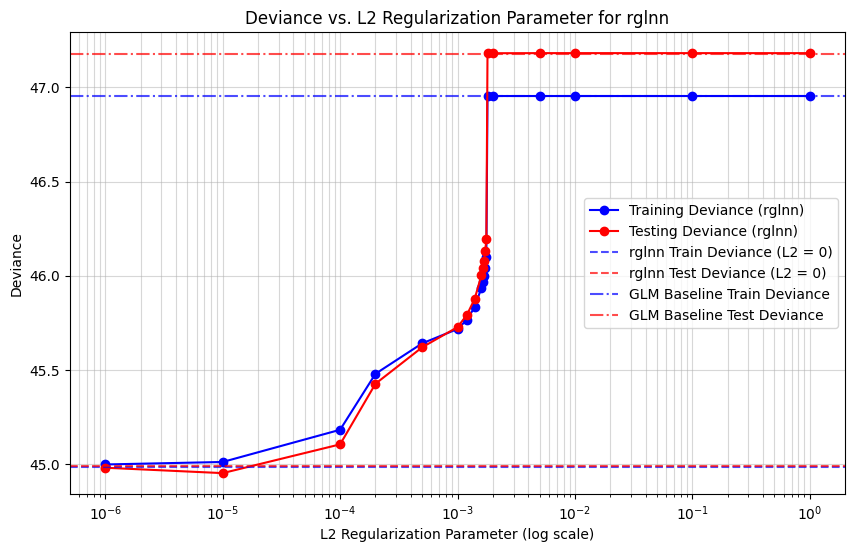

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Filter results to get the rglnn models with non-null numeric regularizers
reg_models = results_df[results_df['name'] == 'rglnn'].copy()
reg_models['regularizer'] = pd.to_numeric(reg_models['regularizer'], errors='coerce')
reg_models = reg_models.dropna(subset=['regularizer']).sort_values('regularizer')

# Separate zero regularization for plotting on log scale
zero_reg = reg_models[reg_models['regularizer'] == 0.0]
non_zero_reg = reg_models[reg_models['regularizer'] > 0.0]

plt.figure(figsize=(10, 6))

# Plot non-zero regularization values on a log scale
plt.plot(non_zero_reg['regularizer'], non_zero_reg['train_deviance'], 'bo-', label='Training Deviance (rglnn)')
plt.plot(non_zero_reg['regularizer'], non_zero_reg['test_deviance'], 'ro-', label='Testing Deviance (rglnn)')

# Highlight the zero regularization case if it exists
if not zero_reg.empty:
    plt.axhline(y=zero_reg['train_deviance'].values[0], color='blue', linestyle='--', alpha=0.7, label='rglnn Train Deviance (L2 = 0)')
    plt.axhline(y=zero_reg['test_deviance'].values[0], color='red', linestyle='--', alpha=0.7, label='rglnn Test Deviance (L2 = 0)')

# Get the baseline GLM (glm1) deviances
glm1_row = results_df[results_df['name'] == 'glm1']
if not glm1_row.empty:
    glm1_train = glm1_row['train_deviance'].values[0]
    glm1_test = glm1_row['test_deviance'].values[0]
    plt.axhline(y=glm1_train, color='blue', linestyle='-.', alpha=0.7, label='GLM Baseline Train Deviance')
    plt.axhline(y=glm1_test, color='red', linestyle='-.', alpha=0.7, label='GLM Baseline Test Deviance')

plt.xscale('log')
plt.xlabel('L2 Regularization Parameter (log scale)')
plt.ylabel('Deviance')
plt.title('Deviance vs. L2 Regularization Parameter for rglnn')
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.savefig('deviance_vs_reg.pdf')
files.download('deviance_vs_reg.pdf')
plt.show()

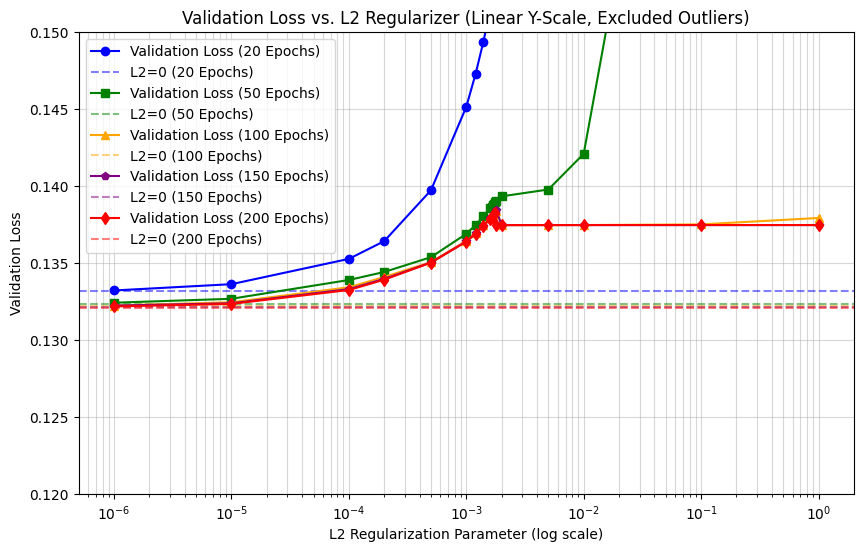

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Filter model_list to get the regularized GLM-NN (rglnn) models that have a training history
rglnn_models = [
    m for m in model_list
    if getattr(m, 'name', None) == 'rglnn'
    and hasattr(m, 'history')
    and 'val_loss' in m.history.history
]

# Collect the regularization parameter and validation loss at epochs 20, 50, 100, 150, 200
plot_data = []
for m in rglnn_models:
    reg_val = float(m.regularizer)

    # Exclude the lambda = 100 case entirely
    if reg_val == 100.0:
        continue

    history = m.history.history['val_loss']
    num_epochs = len(history)

    # Get validation losses safely
    val_20 = history[19] if num_epochs >= 20 else None
    val_50 = history[49] if num_epochs >= 50 else None
    val_100 = history[99] if num_epochs >= 100 else None
    val_150 = history[149] if num_epochs >= 150 else None
    val_200 = history[199] if num_epochs >= 200 else None

    # Specifically exclude epoch 20 validation loss for lambda = 0.1 and lambda = 1
    if reg_val in [0.1, 1.0]:
        val_20 = None

    plot_data.append({
        'regularizer': reg_val,
        'val_20': val_20,
        'val_50': val_50,
        'val_100': val_100,
        'val_150': val_150,
        'val_200': val_200
    })

# Create a DataFrame and sort by the L2 regularization parameter
df_plot = pd.DataFrame(plot_data).sort_values('regularizer')

# Separate zero vs non-zero for log scaling
non_zero_df = df_plot[df_plot['regularizer'] > 0]
zero_df = df_plot[df_plot['regularizer'] == 0]

plt.figure(figsize=(10, 6))

# Define the markers and colors for each epoch checkpoint
checkpoints = [
    ('val_20', '20 Epochs', 'o-', 'blue'),
    ('val_50', '50 Epochs', 's-', 'green'),
    ('val_100', '100 Epochs', '^-', 'orange'),
    ('val_150', '150 Epochs', 'p-', 'purple'),
    ('val_200', '200 Epochs', 'd-', 'red')
]

for col, label, style, color in checkpoints:
    # Mask out NaN values from non_zero_df so line segments connect correctly
    subset = non_zero_df.dropna(subset=[col])

    # Plot non-zero regularization values on a log x-scale
    plt.plot(subset['regularizer'], subset[col], style, color=color, label=f'Validation Loss ({label})')

    # Plot horizontal line for zero-regularization baseline
    if not zero_df.empty and zero_df[col].values[0] is not None:
        plt.axhline(y=zero_df[col].values[0], color=color, linestyle='--', alpha=0.5, label=f'L2=0 ({label})')

plt.xscale('log')
plt.ylim(0.12, 0.15)
plt.xlabel('L2 Regularization Parameter (log scale)')
plt.ylabel('Validation Loss')
plt.title('Validation Loss vs. L2 Regularizer (Linear Y-Scale, Excluded Outliers)')
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.show()

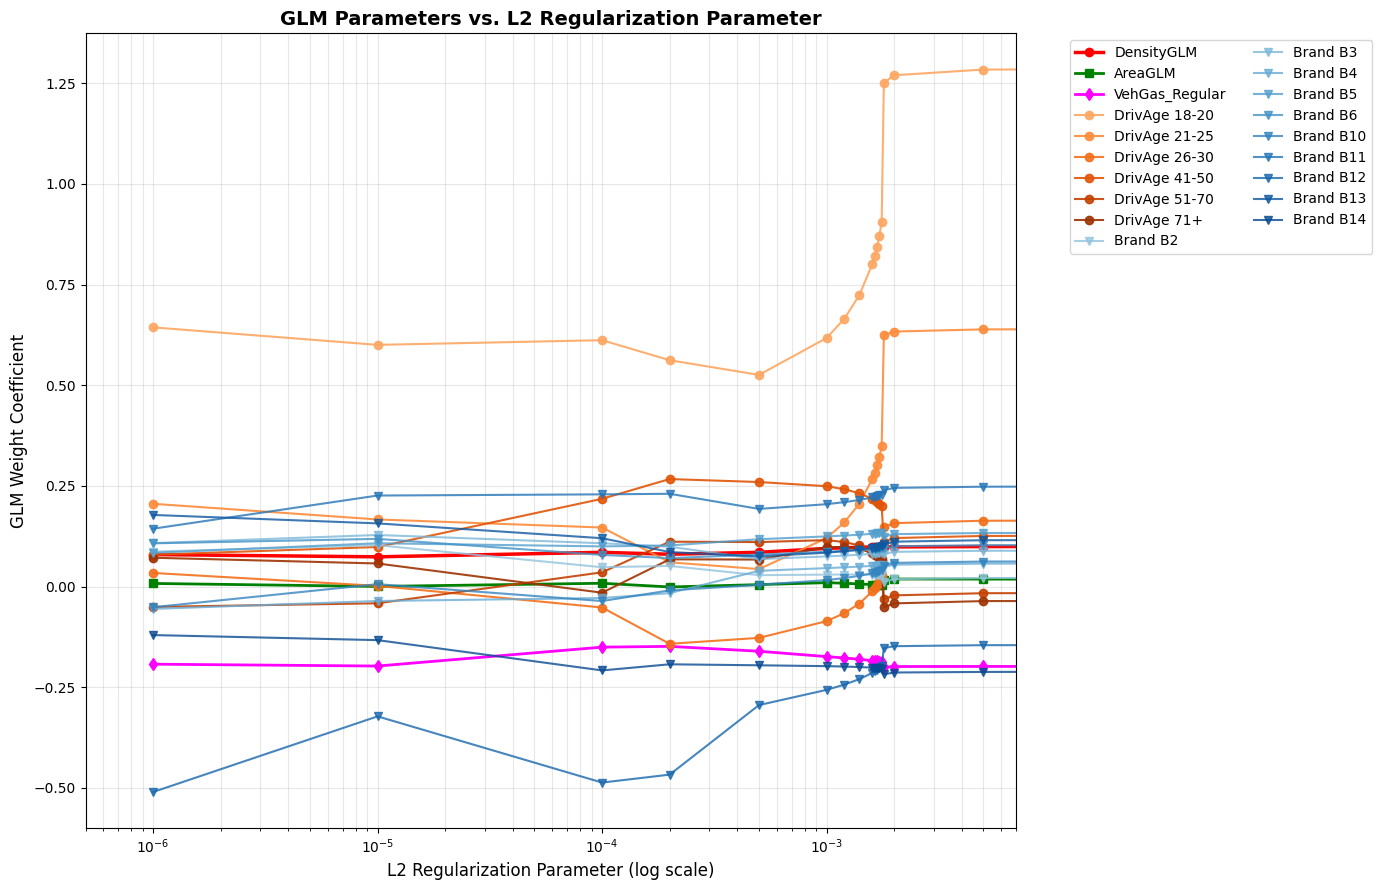

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Filter model_list to get the regularized GLM-NN (rglnn) models
rglnn_models = [
    m for m in model_list
    if getattr(m, 'name', None) == 'rglnn'
    and hasattr(m, 'model')
]

keras_columns = mtpl.training_data_1h.columns.tolist()

# Grouping and finding indices
age_columns = [col for col in keras_columns if col.startswith('DrivAgeGLM_')]
brand_columns = [col for col in keras_columns if col.startswith('VehBrand_')]

density_idx = keras_columns.index('DensityGLM')
area_idx = keras_columns.index('AreaGLM')
gas_idx = keras_columns.index('VehGas_Regular')
age_indices = {col: keras_columns.index(col) for col in age_columns}
brand_indices = {col: keras_columns.index(col) for col in brand_columns}

param_history = []

for m in rglnn_models:
    reg_val = float(m.regularizer)
    glm_layer = m.model.get_layer('glm_linear_predictor')
    weights, bias = glm_layer.get_weights()

    entry = {
        'lambda': reg_val,
        'Intercept': bias[0],
        'DensityGLM': weights[density_idx, 0],
        'AreaGLM': weights[area_idx, 0],
        'VehGas_Regular': weights[gas_idx, 0]
    }
    for col, idx in age_indices.items():
        entry[col] = weights[idx, 0]
    for col, idx in brand_indices.items():
        entry[col] = weights[idx, 0]
    param_history.append(entry)

df_params = pd.DataFrame(param_history).sort_values('lambda')
non_zero_df = df_params[df_params['lambda'] > 0]

plt.figure(figsize=(14, 9))

# 1. Distinct standalone variables
#plt.plot(non_zero_df['lambda'], non_zero_df['Intercept'], 'o-', label='Intercept', color='black', linewidth=2.5)
plt.plot(non_zero_df['lambda'], non_zero_df['DensityGLM'], 'o-', label='DensityGLM', color='red', linewidth=2.5)
plt.plot(non_zero_df['lambda'], non_zero_df['AreaGLM'], 's-', label='AreaGLM', color='green', linewidth=2.0)
plt.plot(non_zero_df['lambda'], non_zero_df['VehGas_Regular'], 'd-', label='VehGas_Regular', color='magenta', linewidth=2.0)

# 2. Driver Age Category Trajectories (Shades of Orange/Red/Gold)
age_colors = plt.cm.Oranges(np.linspace(0.4, 0.9, len(age_columns)))
for i, col in enumerate(age_columns):
    label_name = col.replace('DrivAgeGLM_', 'DrivAge ')
    plt.plot(non_zero_df['lambda'], non_zero_df[col], 'o-', label=label_name, color=age_colors[i], alpha=0.9)

# 3. Vehicle Brand Category Trajectories (Shades of Blue/Cyan)
brand_colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(brand_columns)))
for i, col in enumerate(brand_columns):
    label_name = col.replace('VehBrand_', 'Brand ')
    plt.plot(non_zero_df['lambda'], non_zero_df[col], 'v-', label=label_name, color=brand_colors[i], alpha=0.8)

plt.xscale('log')
plt.xlim(5e-7,7e-3)
plt.xlabel('L2 Regularization Parameter (log scale)', fontsize=12)
plt.ylabel('GLM Weight Coefficient', fontsize=12)
plt.title('GLM Parameters vs. L2 Regularization Parameter', fontsize=14, fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2)
plt.grid(True, which="both", ls="-", alpha=0.3)
plt.tight_layout()
plt.show()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

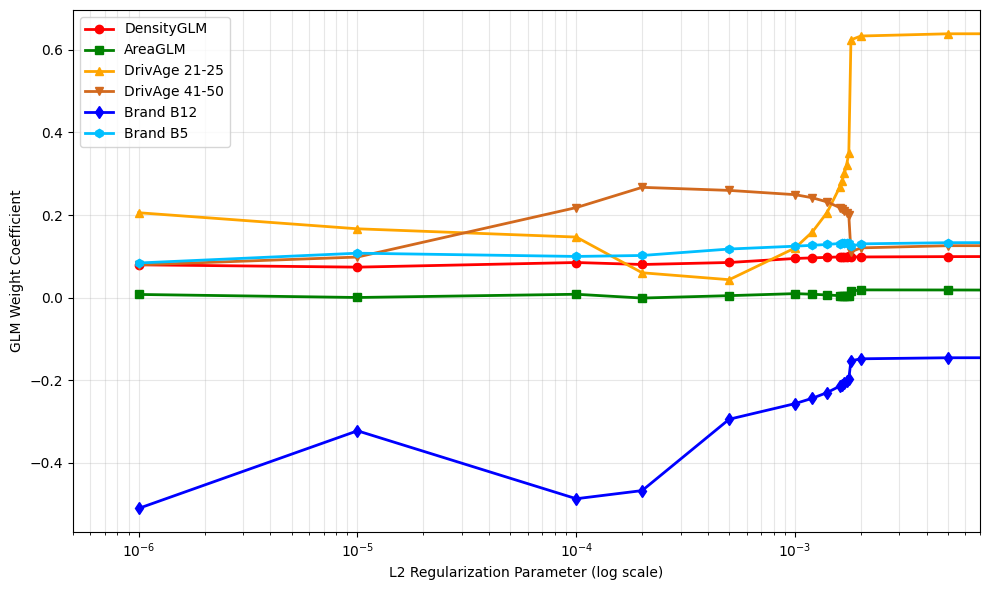

In [ ]:
plt.figure(figsize=(10, 6))

# Filter to requested columns
requested_cols = {
    'DensityGLM': ('DensityGLM', 'o-', 'red'),
    'AreaGLM': ('AreaGLM', 's-', 'green'),
    'DrivAgeGLM_21-25': ('DrivAge 21-25', '^-', 'orange'),
    'DrivAgeGLM_41-50': ('DrivAge 41-50', 'v-', 'chocolate'),
    'VehBrand_B12': ('Brand B12', 'd-', 'blue'),
    'VehBrand_B5': ('Brand B5', 'h-', 'deepskyblue')
}

for col, (label, marker, color) in requested_cols.items():
    if col in non_zero_df.columns:
        plt.plot(non_zero_df['lambda'], non_zero_df[col], marker, label=label, color=color, linewidth=2.0)

plt.xscale('log')
plt.xlim(5e-7, 7e-3)
plt.xlabel('L2 Regularization Parameter (log scale)')
plt.ylabel('GLM Weight Coefficient')
#plt.title('Subset of GLM Parameters vs. L2 Regularization Parameter', fontsize=14, fontweight='bold')
plt.legend(loc='best')
plt.grid(True, which="both", ls="-", alpha=0.3)
plt.tight_layout()
plt.savefig('glmbeta_vs_reg.pdf')
files.download('glmbeta_vs_reg.pdf')
plt.show()

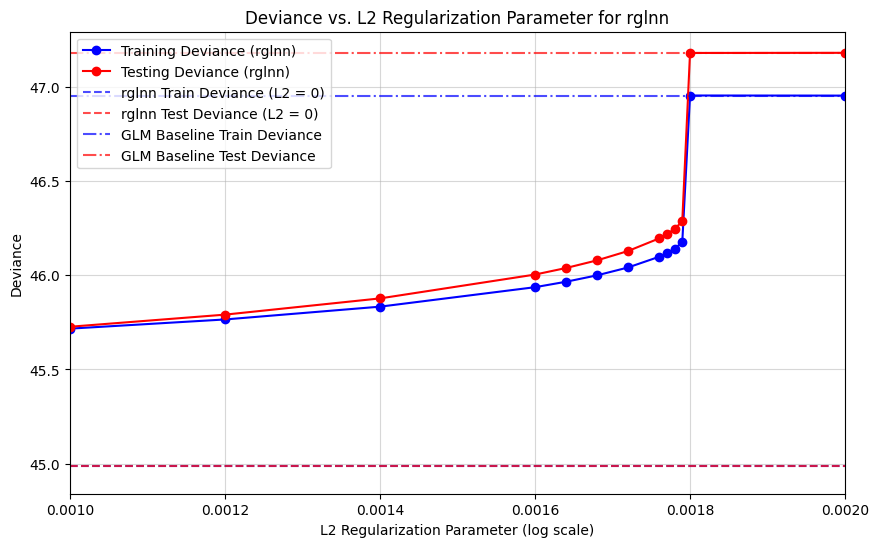

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Filter results to get the rglnn models with non-null numeric regularizers
reg_models = results_df[results_df['name'] == 'rglnn'].copy()
reg_models['regularizer'] = pd.to_numeric(reg_models['regularizer'], errors='coerce')
reg_models = reg_models.dropna(subset=['regularizer']).sort_values('regularizer')

# Separate zero regularization for plotting on log scale
zero_reg = reg_models[reg_models['regularizer'] == 0.0]
non_zero_reg = reg_models[reg_models['regularizer'] > 0.0]

plt.figure(figsize=(10, 6))

# Plot non-zero regularization values on a log scale
plt.plot(non_zero_reg['regularizer'], non_zero_reg['train_deviance'], 'bo-', label='Training Deviance (rglnn)')
plt.plot(non_zero_reg['regularizer'], non_zero_reg['test_deviance'], 'ro-', label='Testing Deviance (rglnn)')

# Highlight the zero regularization case if it exists
if not zero_reg.empty:
    plt.axhline(y=zero_reg['train_deviance'].values[0], color='blue', linestyle='--', alpha=0.7, label='rglnn Train Deviance (L2 = 0)')
    plt.axhline(y=zero_reg['test_deviance'].values[0], color='red', linestyle='--', alpha=0.7, label='rglnn Test Deviance (L2 = 0)')

# Get the baseline GLM (glm1) deviances
glm1_row = results_df[results_df['name'] == 'glm1']
if not glm1_row.empty:
    glm1_train = glm1_row['train_deviance'].values[0]
    glm1_test = glm1_row['test_deviance'].values[0]
    plt.axhline(y=glm1_train, color='blue', linestyle='-.', alpha=0.7, label='GLM Baseline Train Deviance')
    plt.axhline(y=glm1_test, color='red', linestyle='-.', alpha=0.7, label='GLM Baseline Test Deviance')

plt.xlim(1.0e-3, 2.0e-3)
plt.xlabel('L2 Regularization Parameter (log scale)')
plt.ylabel('Deviance')
plt.title('Deviance vs. L2 Regularization Parameter for rglnn')
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.show()

In [ ]:
QUICK_MODE = False

In [ ]:
def fnn_correction(model_info):
  intermediate_model = keras.Model(
      inputs=model_info.model.inputs,
      outputs=[
          model_info.model.get_layer("glm_linear_predictor").output,
          model_info.model.get_layer("fnn_linear_predictor").output,
          model_info.model.output,
      ]
  )

  glm_eta, fnn_eta, prediction = intermediate_model(model_info.train.input, training=False)

  f = fnn_eta.numpy().ravel()

  return f.mean(), f.std(), (f**2).mean()**0.5, f


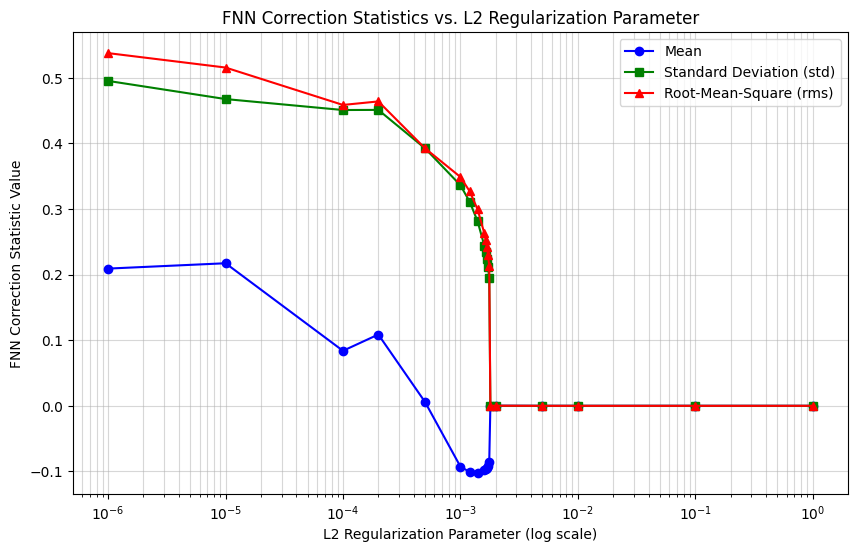

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Filter model_list to get the regularized GLM-NN (rglnn) models
rglnn_models = [
    m for m in model_list
    if getattr(m, 'name', None) == 'rglnn'
    and hasattr(m, 'history')
]

stats_data = []
for m in rglnn_models:
    reg_val = float(m.regularizer)
    # Calculate mean, std, and rms using the defined fnn_correction function
    f_mean, f_std, f_rms, _ = fnn_correction(m)
    stats_data.append({
        'regularizer': reg_val,
        'mean': f_mean,
        'std': f_std,
        'rms': f_rms
    })

# Create a DataFrame and sort by the L2 regularization parameter
df_stats = pd.DataFrame(stats_data).sort_values('regularizer')

# Separate zero vs non-zero for log scaling on the x-axis
non_zero_df = df_stats[df_stats['regularizer'] > 0]
zero_df = df_stats[df_stats['regularizer'] == 0]

plt.figure(figsize=(10, 6))

# Plot the three statistics
plt.plot(non_zero_df['regularizer'], non_zero_df['mean'], 'o-', color='blue', label='Mean')
plt.plot(non_zero_df['regularizer'], non_zero_df['std'], 's-', color='green', label='Standard Deviation (std)')
plt.plot(non_zero_df['regularizer'], non_zero_df['rms'], '^-', color='red', label='Root-Mean-Square (rms)')

plt.xscale('log')
plt.xlabel('L2 Regularization Parameter (log scale)')
plt.ylabel('FNN Correction Statistic Value')
plt.title('FNN Correction Statistics vs. L2 Regularization Parameter')
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.savefig('fnn_correction_stats.pdf')
plt.show()
files.download('fnn_correction_stats.pdf')

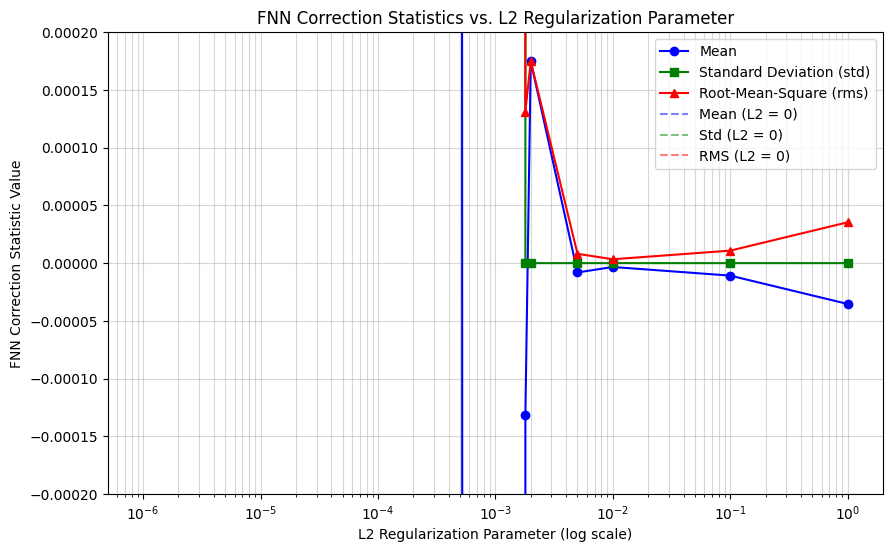

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Filter model_list to get the regularized GLM-NN (rglnn) models
rglnn_models = [
    m for m in model_list
    if getattr(m, 'name', None) == 'rglnn'
    and hasattr(m, 'history')
]

stats_data = []
for m in rglnn_models:
    reg_val = float(m.regularizer)
    # Calculate mean, std, and rms using the defined fnn_correction function
    f_mean, f_std, f_rms, _ = fnn_correction(m)
    stats_data.append({
        'regularizer': reg_val,
        'mean': f_mean,
        'std': f_std,
        'rms': f_rms
    })

# Create a DataFrame and sort by the L2 regularization parameter
df_stats = pd.DataFrame(stats_data).sort_values('regularizer')

# Separate zero vs non-zero for log scaling on the x-axis
non_zero_df = df_stats[df_stats['regularizer'] > 0]
zero_df = df_stats[df_stats['regularizer'] == 0]

plt.figure(figsize=(10, 6))

# Plot the three statistics
plt.plot(non_zero_df['regularizer'], non_zero_df['mean'], 'o-', color='blue', label='Mean')
plt.plot(non_zero_df['regularizer'], non_zero_df['std'], 's-', color='green', label='Standard Deviation (std)')
plt.plot(non_zero_df['regularizer'], non_zero_df['rms'], '^-', color='red', label='Root-Mean-Square (rms)')

# If zero regularization exists, plot as baseline horizontal lines
if not zero_df.empty:
    plt.axhline(y=zero_df['mean'].values[0], color='blue', linestyle='--', alpha=0.5, label='Mean (L2 = 0)')
    plt.axhline(y=zero_df['std'].values[0], color='green', linestyle='--', alpha=0.5, label='Std (L2 = 0)')
    plt.axhline(y=zero_df['rms'].values[0], color='red', linestyle='--', alpha=0.5, label='RMS (L2 = 0)')

plt.xscale('log')
plt.xlabel('L2 Regularization Parameter (log scale)')
plt.ylabel('FNN Correction Statistic Value')
plt.ylim(-2e-4, 2e-4)
plt.title('FNN Correction Statistics vs. L2 Regularization Parameter')
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.show()

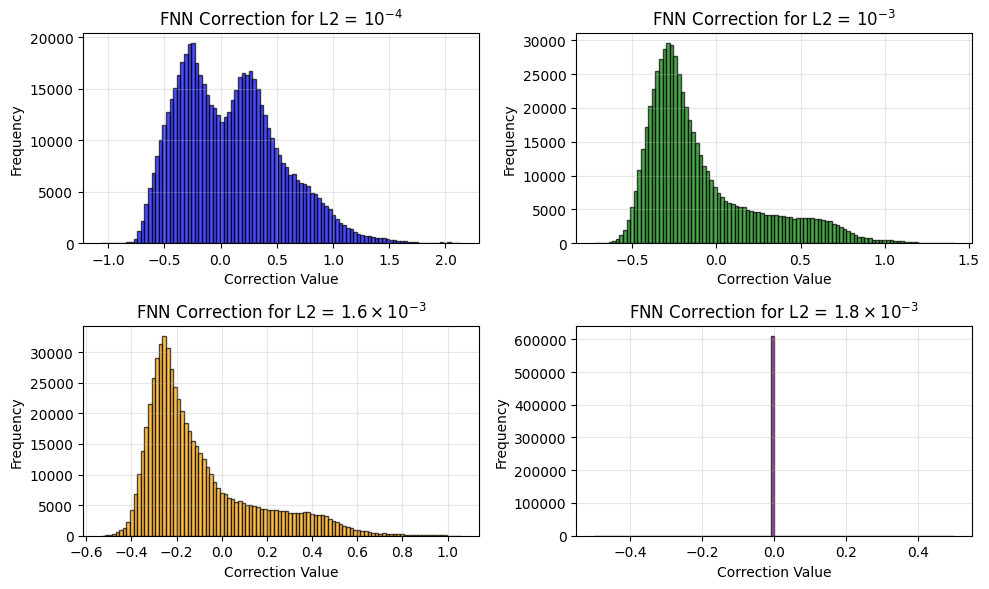

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt

# Find the models for the specified L2 regularizers
model_1e4 = next(m for m in model_list if getattr(m, 'name', None) == 'rglnn' and abs(float(m.regularizer) - 1e-4) < 1e-9)
model_1e3 = next(m for m in model_list if getattr(m, 'name', None) == 'rglnn' and abs(float(m.regularizer) - 1e-3) < 1e-9)
model_16e3 = next(m for m in model_list if getattr(m, 'name', None) == 'rglnn' and abs(float(m.regularizer) - 1.6e-3) < 1e-9)
model_18e3 = next(m for m in model_list if getattr(m, 'name', None) == 'rglnn' and abs(float(m.regularizer) - 1.8e-3) < 1e-9)

# Compute fnn_eta for all models using the defined fnn_correction function
_, _, _, fnn_eta_1e4 = fnn_correction(model_1e4)
_, _, _, fnn_eta_1e3 = fnn_correction(model_1e3)
_, _, _, fnn_eta_16e3 = fnn_correction(model_16e3)
_, _, _, fnn_eta_18e3 = fnn_correction(model_18e3)

# Create a 2x2 grid of histograms
fig, axes = plt.subplots(2, 2, figsize=(10,6))

# Subplot 1: L2 = 1e-4
axes[0, 0].hist(fnn_eta_1e4, bins=100, color='blue', alpha=0.7, edgecolor='black')
axes[0, 0].set_title('FNN Correction for L2 = $10^{-4}$')
axes[0, 0].set_xlabel('Correction Value')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].grid(True, alpha=0.3)

# Subplot 2: L2 = 1e-3
axes[0, 1].hist(fnn_eta_1e3, bins=100, color='green', alpha=0.7, edgecolor='black')
axes[0, 1].set_title('FNN Correction for L2 = $10^{-3}$')
axes[0, 1].set_xlabel('Correction Value')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].grid(True, alpha=0.3)

# Subplot 3: L2 = 1.6e-3
axes[1, 0].hist(fnn_eta_16e3, bins=100, color='orange', alpha=0.7, edgecolor='black')
axes[1, 0].set_title('FNN Correction for L2 = $1.6 \\times 10^{-3}$')
axes[1, 0].set_xlabel('Correction Value')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].grid(True, alpha=0.3)

# Subplot 4: L2 = 1.8e-3
axes[1, 1].hist(fnn_eta_18e3, bins=100, color='purple', alpha=0.7, edgecolor='black')
axes[1, 1].set_title('FNN Correction for L2 = $1.8 \\times 10^{-3}$')
axes[1, 1].set_xlabel('Correction Value')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fnn_correction_histograms.pdf')
plt.show()
files.download('fnn_correction_histograms.pdf')

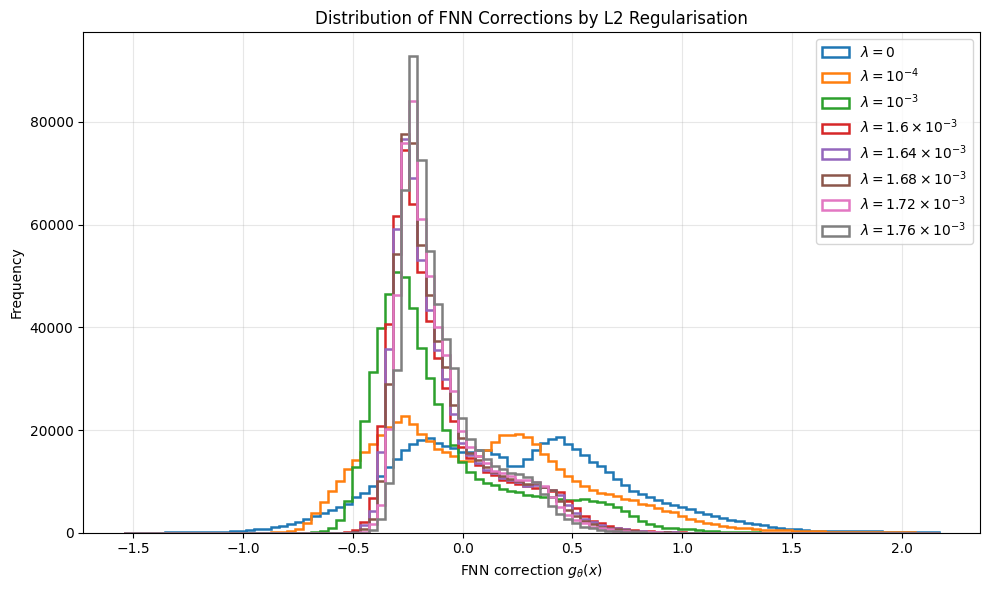

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

_, _, _, fnn_eta_zero = fnn_correction(next(m for m in model_list if getattr(m, 'name', None) == 'rglnn' and abs(float(m.regularizer)) < 1e-9))
_, _, _, fnn_eta_164 = fnn_correction(next(m for m in model_list if getattr(m, 'name', None) == 'rglnn' and abs(float(m.regularizer) - 1.64e-3) < 1e-9))
_, _, _, fnn_eta_168 = fnn_correction(next(m for m in model_list if getattr(m, 'name', None) == 'rglnn' and abs(float(m.regularizer) - 1.68e-3) < 1e-9))
_, _, _, fnn_eta_172 = fnn_correction(next(m for m in model_list if getattr(m, 'name', None) == 'rglnn' and abs(float(m.regularizer) - 1.72e-3) < 1e-9))
_, _, _, fnn_eta_176 = fnn_correction(next(m for m in model_list if getattr(m, 'name', None) == 'rglnn' and abs(float(m.regularizer) - 1.76e-3) < 1e-9))

data = [
    (fnn_eta_zero, r"$\lambda=0$"),
    (fnn_eta_1e4, r"$\lambda=10^{-4}$"),
    (fnn_eta_1e3, r"$\lambda=10^{-3}$"),
    (fnn_eta_16e3, r"$\lambda=1.6\times10^{-3}$"),
    (fnn_eta_164, r"$\lambda=1.64\times10^{-3}$"),
    (fnn_eta_168, r"$\lambda=1.68\times10^{-3}$"),
    (fnn_eta_172, r"$\lambda=1.72\times10^{-3}$"),
    (fnn_eta_176, r"$\lambda=1.76\times10^{-3}$"),
]

# Common bin boundaries
values = np.concatenate([d.ravel() for d, _ in data])
bins = np.linspace(values.min(), values.max(), 101)

plt.figure(figsize=(10, 6))

for corrections, label in data:
    plt.hist(
        corrections.numpy().ravel() if hasattr(corrections, "numpy")
        else np.asarray(corrections).ravel(),
        bins=bins,
        histtype="step",
        linewidth=1.8,
        label=label
    )

plt.xlabel(r"FNN correction $g_\theta(x)$")
plt.ylabel("Frequency")
plt.title("Distribution of FNN Corrections by L2 Regularisation")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

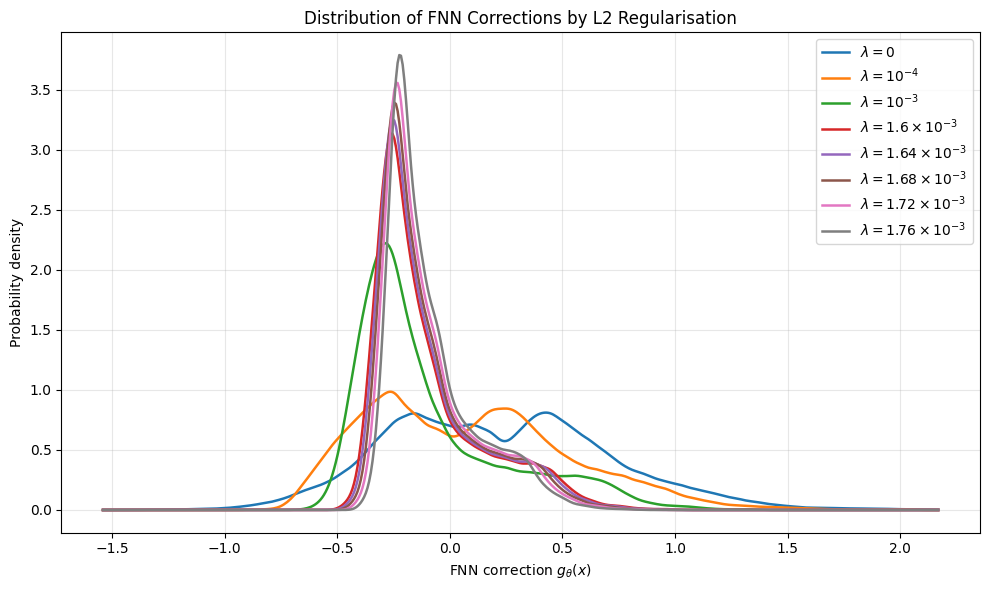

In [ ]:
from scipy.ndimage import gaussian_filter1d

# Common bin boundaries
arrays = [
    d.numpy().ravel() if hasattr(d, "numpy")
    else np.asarray(d).ravel()
    for d, _ in data
]

values = np.concatenate(arrays)
bins = np.linspace(values.min(), values.max(), 501)
centres = (bins[:-1] + bins[1:]) / 2

plt.figure(figsize=(10, 6))

for (corrections, label), f in zip(data, arrays):
    density, _ = np.histogram(f, bins=bins, density=True)
    smooth = gaussian_filter1d(density, sigma=3)

    plt.plot(centres, smooth, linewidth=1.8, label=label)

plt.xlabel(r"FNN correction $g_\theta(x)$")
plt.ylabel("Probability density")
plt.title("Distribution of FNN Corrections by L2 Regularisation")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
layer = model_info.model.get_layer("fnn_linear_predictor")
print(layer.bias)
print(layer.weights)

None
[<Variable path=fnn_linear_predictor/kernel, shape=(10, 1), dtype=float32, value=[[ 0.00010691]
 [ 0.00013744]
 [ 0.00013333]
 [-0.00011514]
 [ 0.00011844]
 [-0.00013165]
 [ 0.00011388]
 [-0.00012234]
 [-0.00012257]
 [ 0.00013829]]>]


In [ ]:
glm_eta

NameError: name 'glm_eta' is not defined

In [ ]:
print(results_df.to_csv())